# Homework 7

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### (a) Load the Data and Create the Training and Test Sets

I use the Anuran Calls (MFCCs) dataset. Each row contains 22 MFCC features from a frog call syllable. The three target labels are Family, Genus, and Species.

I use the MFCC features as inputs. I leave out RecordID because it identifies the original recording.

I randomly split the data into 70% training data and 30% test data. I stratify by Species to keep similar class proportions in both sets. I use a fixed random seed so I can repeat the split.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

data_path = Path("data") / "Frogs_MFCCs.csv"
df = pd.read_csv(data_path)

label_cols = ["Family", "Genus", "Species"]
feature_cols = [col for col in df.columns if col.startswith("MFCCs")]

X = df[feature_cols].copy()
y = df[label_cols].copy()

print("Dataset shape:", df.shape)
print("Number of features:", X.shape[1])
print("Missing values:", df.isna().sum().sum())

display(df.head())
display(y.nunique().rename("Number of classes").to_frame())

Dataset shape: (7195, 26)
Number of features: 22
Missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


,Number of classes
Family,4
Genus,8
Species,10


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.70,
    random_state=RANDOM_STATE,
    stratify=y["Species"]
)

split_summary = pd.DataFrame(
    {
        "Samples": [len(X_train), len(X_test)],
        "Features": [X_train.shape[1], X_test.shape[1]],
        "Share": [len(X_train) / len(X), len(X_test) / len(X)]
    },
    index=["Training", "Test"]
)

display(split_summary.round(4))

,Samples,Features,Share
Training,5036,22,0.6999
Test,2159,22,0.3001


### (b) Classification with Separate Models

#### (i) Evaluation Metrics

I train a separate classifier for Family, Genus, and Species. I combine their predictions into one label triplet for each sample.

I use the following metrics:

- Exact Match: the fraction of samples with all three labels predicted correctly.
- Hamming Distance: the average number of wrong labels per sample. It ranges from 0 to 3.
- Hamming Loss: the fraction of wrong labels across all samples and all three targets.
- Hamming Score: I define this as 1 minus Hamming Loss. It is the fraction of correct labels.

I also report Sample Jaccard. For each sample, I divide the number of shared labels by the number of labels in the union of the true and predicted sets. I treat Family, Genus, and Species as separate label types, then average the scores across samples.

Higher Exact Match, Hamming Score, and Sample Jaccard are better. Lower Hamming Distance and Hamming Loss are better.

References:
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.jaccard_score.html

In [4]:
def evaluate_predictions(y_true, y_pred):
    matches = np.asarray(y_true) == np.asarray(y_pred)
    correct_per_sample = matches.sum(axis=1)
    n_labels = matches.shape[1]

    return pd.Series({
        "Exact Match": matches.all(axis=1).mean(),
        "Hamming Distance": (~matches).sum(axis=1).mean(),
        "Hamming Loss": (~matches).mean(),
        "Hamming Score": matches.mean(),
        "Sample Jaccard": (
            correct_per_sample / (2 * n_labels - correct_per_sample)
        ).mean()
    })

#### (ii) Gaussian Kernel SVM

I use an RBF kernel, which is a Gaussian kernel. For each target, I use one-versus-rest classification.

I standardize the features inside a Pipeline. During cross-validation, the scaler is fitted only on each training fold.

I select C and gamma using 10-fold stratified cross-validation. C controls the penalty for classification errors. Gamma controls the kernel width, with gamma = 1 / (2 * sigma^2).

I search C in {0.1, 1, 10, 100, 1000} and gamma in {0.001, 0.01, 0.1, 1}. I choose the pair with the highest mean cross-validation accuracy for each target.

I check the search results before using the test set. If a best value is at the edge of the grid, I check whether the range needs to be expanded.

In [5]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

cv10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE
)

rbf_grid = {
    "svm__estimator__C": [0.1, 1, 10, 100, 1000],
    "svm__estimator__gamma": [0.001, 0.01, 0.1, 1]
}

rbf_searches = {}
rbf_rows = []

for label in label_cols:
    print(f"Training RBF SVM for {label}...", flush=True)

    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("svm", OneVsRestClassifier(
            SVC(kernel="rbf", cache_size=200),
            n_jobs=1
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=rbf_grid,
        scoring="accuracy",
        cv=cv10,
        n_jobs=4,
        pre_dispatch=4,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train[label])
    rbf_searches[label] = search

    best_c = search.best_params_["svm__estimator__C"]
    best_gamma = search.best_params_["svm__estimator__gamma"]

    rbf_rows.append({
        "Target": label,
        "C": best_c,
        "Gamma": best_gamma,
        "Sigma": np.sqrt(1 / (2 * best_gamma)),
        "CV Accuracy": search.best_score_,
        "CV Std": search.cv_results_["std_test_score"][search.best_index_]
    })

    print(
        f"{label} finished. "
        f"C={best_c}, gamma={best_gamma}, "
        f"CV accuracy={search.best_score_:.4f}",
        flush=True
    )

rbf_cv_summary = pd.DataFrame(rbf_rows).set_index("Target")
display(rbf_cv_summary.round(4))

Training RBF SVM for Family...
Fitting 10 folds for each of 20 candidates, totalling 200 fits
Family finished. C=100, gamma=0.01, CV accuracy=0.9899
Training RBF SVM for Genus...
Fitting 10 folds for each of 20 candidates, totalling 200 fits
Genus finished. C=10, gamma=0.1, CV accuracy=0.9885
Training RBF SVM for Species...
Fitting 10 folds for each of 20 candidates, totalling 200 fits
Species finished. C=1000, gamma=0.01, CV accuracy=0.9871


,C,Gamma,Sigma,CV Accuracy,CV Std
Target,,,,,
Family,100,0.01,7.0711,0.9899,0.0035
Genus,10,0.10,2.2361,0.9885,0.0039
Species,1000,0.01,7.0711,0.9871,0.0042


The best C for Species is 1000, which is the largest value in the first grid. I check C values of 10000 and 100000 using the same gamma values and the same cross-validation folds.

I keep the original model unless the new search gives a higher mean cross-validation accuracy. I do not use the test set to make this choice.

In [6]:
from sklearn.base import clone

species_initial_search = rbf_searches["Species"]

species_extra_grid = {
    "svm__estimator__C": [10000, 100000],
    "svm__estimator__gamma": [0.001, 0.01, 0.1, 1]
}

species_extra_search = GridSearchCV(
    estimator=clone(species_initial_search.best_estimator_),
    param_grid=species_extra_grid,
    scoring="accuracy",
    cv=cv10,
    n_jobs=4,
    pre_dispatch=4,
    verbose=1,
    error_score="raise"
)

species_extra_search.fit(X_train, y_train["Species"])

species_grid_results = pd.DataFrame(
    species_extra_search.cv_results_
)

display(
    species_grid_results[
        [
            "param_svm__estimator__C",
            "param_svm__estimator__gamma",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    ).reset_index(drop=True).round(6)
)

print(
    "Original best CV accuracy:",
    round(species_initial_search.best_score_, 6)
)

print(
    "Extra search best CV accuracy:",
    round(species_extra_search.best_score_, 6)
)

if species_extra_search.best_score_ > species_initial_search.best_score_:
    rbf_searches["Species"] = species_extra_search

print(
    "Selected Species parameters:",
    rbf_searches["Species"].best_params_
)

Fitting 10 folds for each of 8 candidates, totalling 80 fits


,param_svm__estimator__C,param_svm__estimator__gamma,mean_test_score,std_test_score
0,10000,0.010,0.987092,0.004191
1,100000,0.010,0.987092,0.004191
2,100000,0.100,0.986300,0.004475
3,10000,0.100,0.986300,0.004475
4,10000,0.001,0.984907,0.004886
5,100000,0.001,0.984907,0.005421
6,10000,1.000,0.884232,0.015621
7,100000,1.000,0.884232,0.015621


Original best CV accuracy: 0.987092
Extra search best CV accuracy: 0.987092
Selected Species parameters: {'svm__estimator__C': 1000, 'svm__estimator__gamma': 0.01}


The larger C values did not improve the best cross-validation accuracy for Species. The best score stayed at 0.987092, so I keep C = 1000 and gamma = 0.01.

The selected parameters are:
- Family: C = 100, gamma = 0.01.
- Genus: C = 10, gamma = 0.1.
- Species: C = 1000, gamma = 0.01.

I now use these models to predict the test labels.

In [7]:
rbf_predictions = pd.DataFrame(
    {
        label: rbf_searches[label].predict(X_test)
        for label in label_cols
    },
    index=y_test.index
)

rbf_target_results = pd.DataFrame(
    {
        "CV Accuracy": [
            rbf_searches[label].best_score_
            for label in label_cols
        ],
        "Test Accuracy": [
            (y_test[label] == rbf_predictions[label]).mean()
            for label in label_cols
        ]
    },
    index=label_cols
)

rbf_results = evaluate_predictions(
    y_test[label_cols],
    rbf_predictions[label_cols]
).to_frame().T

rbf_results.index = ["RBF SVM"]

print("Accuracy for each target:")
display(rbf_target_results.round(4))

print("Combined test results:")
display(rbf_results.round(4))

Accuracy for each target:


,CV Accuracy,Test Accuracy
Family,0.9899,0.9926
Genus,0.9885,0.9907
Species,0.9871,0.9898


Combined test results:


,Exact Match,Hamming Distance,Hamming Loss,Hamming Score,Sample Jaccard
RBF SVM,0.9852,0.0269,0.009,0.991,0.9893


The RBF SVM gives test accuracies of 0.9926 for Family, 0.9907 for Genus, and 0.9898 for Species.

The Exact Match is 0.9852, so all three labels are correct for about 98.52% of the test samples. The Hamming Score is 0.9910, and the Hamming Loss is about 0.0090.

The test accuracies are close to the cross-validation accuracies. The models perform well on this random split.

#### (iii) L1-Penalized Linear SVM

I train a separate L1-penalized linear SVM for each target. Each model uses one-versus-rest classification. The L1 penalty can set some feature coefficients to zero.

I standardize the features inside a Pipeline. The scaler is fitted only on the training fold during cross-validation.

I select C from {0.001, 0.01, 0.1, 1, 10, 100, 1000} using 10-fold stratified cross-validation. I use the same data split and evaluation metrics as before.

Reference:
- https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html

In [8]:
from sklearn.svm import LinearSVC

l1_grid = {
    "svm__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

l1_searches = {}
l1_rows = []

for label in label_cols:
    print(f"Training L1 linear SVM for {label}...", flush=True)

    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            loss="squared_hinge",
            dual=False,
            multi_class="ovr",
            tol=1e-4,
            max_iter=50000,
            random_state=RANDOM_STATE
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=l1_grid,
        scoring="accuracy",
        cv=cv10,
        n_jobs=4,
        pre_dispatch=4,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train[label])
    l1_searches[label] = search

    best_model = search.best_estimator_.named_steps["svm"]

    l1_rows.append({
        "Target": label,
        "C": search.best_params_["svm__C"],
        "CV Accuracy": search.best_score_,
        "CV Std": search.cv_results_["std_test_score"][search.best_index_],
        "Iterations": best_model.n_iter_
    })

    print(
        f"{label} finished. "
        f"C={search.best_params_['svm__C']}, "
        f"CV accuracy={search.best_score_:.4f}",
        flush=True
    )

l1_cv_summary = pd.DataFrame(l1_rows).set_index("Target")
display(l1_cv_summary.round(4))

Training L1 linear SVM for Family...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Family finished. C=1, CV accuracy=0.9343
Training L1 linear SVM for Genus...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Genus finished. C=100, CV accuracy=0.9533
Training L1 linear SVM for Species...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Species finished. C=100, CV accuracy=0.9573


,C,CV Accuracy,CV Std,Iterations
Target,,,,
Family,1,0.9343,0.0112,1545
Genus,100,0.9533,0.0094,1592
Species,100,0.9573,0.0090,1586


The selected C values are 1 for Family, 100 for Genus, and 100 for Species. None of these values is at the edge of the search grid.

The L1 linear SVM has lower cross-validation accuracy than the RBF SVM for all three targets. I now evaluate it on the same test set.

In [9]:
l1_predictions = pd.DataFrame(
    {
        label: l1_searches[label].predict(X_test)
        for label in label_cols
    },
    index=y_test.index
)

l1_target_results = pd.DataFrame(
    {
        "CV Accuracy": [
            l1_searches[label].best_score_
            for label in label_cols
        ],
        "Test Accuracy": [
            (y_test[label] == l1_predictions[label]).mean()
            for label in label_cols
        ]
    },
    index=label_cols
)

l1_results = evaluate_predictions(
    y_test[label_cols],
    l1_predictions[label_cols]
).to_frame().T

l1_results.index = ["L1 Linear SVM"]

comparison_results = pd.concat([
    rbf_results,
    l1_results
])

print("L1 linear SVM accuracy for each target:")
display(l1_target_results.round(4))

print("Combined test results:")
display(comparison_results.round(4))

L1 linear SVM accuracy for each target:


,CV Accuracy,Test Accuracy
Family,0.9343,0.9393
Genus,0.9533,0.9486
Species,0.9573,0.9597


Combined test results:


,Exact Match,Hamming Distance,Hamming Loss,Hamming Score,Sample Jaccard
RBF SVM,0.9852,0.0269,0.0090,0.9910,0.9893
L1 Linear SVM,0.9171,0.1524,0.0508,0.9492,0.9400


The L1 linear SVM gives test accuracies of 0.9393 for Family, 0.9486 for Genus, and 0.9597 for Species.

Its Exact Match is 0.9171, compared with 0.9852 for the RBF SVM. Its Hamming Loss is 0.0508, which is higher than the RBF model's loss of 0.0090. The RBF SVM performs better on this split.

#### (iv) L1-Penalized Linear SVM with SMOTE

The classes have different numbers of training samples. I use SMOTE to create synthetic samples for the smaller classes.

I apply SMOTE separately for Family, Genus, and Species. I use five nearest neighbors and increase each smaller class to the size of the largest class for that target.

The Pipeline first standardizes the features, then applies SMOTE, and finally fits the L1 linear SVM. During cross-validation, scaling and SMOTE are fitted only on each training fold. The validation and test sets keep their original samples.

I select C using the same grid and 10-fold stratified cross-validation as before.

References:
- https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html
- https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html

In [10]:
balance_rows = []

for label in label_cols:
    counts = y_train[label].value_counts()

    balance_rows.append({
        "Target": label,
        "Classes": len(counts),
        "Smallest Class": counts.min(),
        "Largest Class": counts.max(),
        "Largest / Smallest": counts.max() / counts.min()
    })

class_balance = pd.DataFrame(balance_rows).set_index("Target")
display(class_balance.round(2))

,Classes,Smallest Class,Largest Class,Largest / Smallest
Target,,,,
Family,4,48,3093,64.44
Genus,8,48,2904,60.50
Species,10,48,2434,50.71


In [11]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_searches = {}
smote_rows = []

for label in label_cols:
    print(f"Training SMOTE + L1 SVM for {label}...", flush=True)

    pipeline = ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(
            sampling_strategy="auto",
            k_neighbors=5,
            random_state=RANDOM_STATE
        )),
        ("svm", LinearSVC(
            penalty="l1",
            loss="squared_hinge",
            dual=False,
            multi_class="ovr",
            tol=1e-4,
            max_iter=50000,
            random_state=RANDOM_STATE
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=l1_grid,
        scoring="accuracy",
        cv=cv10,
        n_jobs=4,
        pre_dispatch=4,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train[label])
    smote_searches[label] = search

    best_model = search.best_estimator_.named_steps["svm"]

    smote_rows.append({
        "Target": label,
        "C": search.best_params_["svm__C"],
        "CV Accuracy": search.best_score_,
        "CV Std": search.cv_results_["std_test_score"][search.best_index_],
        "Iterations": best_model.n_iter_
    })

    print(
        f"{label} finished. "
        f"C={search.best_params_['svm__C']}, "
        f"CV accuracy={search.best_score_:.4f}",
        flush=True
    )

smote_cv_summary = pd.DataFrame(smote_rows).set_index("Target")
display(smote_cv_summary.round(4))

Training SMOTE + L1 SVM for Family...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Family finished. C=100, CV accuracy=0.9148
Training SMOTE + L1 SVM for Genus...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Genus finished. C=1, CV accuracy=0.9146
Training SMOTE + L1 SVM for Species...
Fitting 10 folds for each of 7 candidates, totalling 70 fits
Species finished. C=1, CV accuracy=0.9533


,C,CV Accuracy,CV Std,Iterations
Target,,,,
Family,100,0.9148,0.0095,1418
Genus,1,0.9146,0.0054,1964
Species,1,0.9533,0.0094,2972


The smallest class has 48 training samples for each target. The largest class is more than 50 times larger than the smallest class for all three targets.

With SMOTE, the selected C values are 100 for Family, 1 for Genus, and 1 for Species. These values are inside the search grid.

I compare all three methods on the same test set. I also report Macro Recall and Macro F1 for each target. These metrics give each class equal weight, so large classes do not dominate the averages.

References:
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html

In [12]:
from sklearn.metrics import recall_score, f1_score

smote_predictions = pd.DataFrame(
    {
        label: smote_searches[label].predict(X_test)
        for label in label_cols
    },
    index=y_test.index
)

smote_results = evaluate_predictions(
    y_test[label_cols],
    smote_predictions[label_cols]
).to_frame().T

smote_results.index = ["SMOTE + L1 SVM"]

comparison_results = pd.concat([
    rbf_results,
    l1_results,
    smote_results
])

model_predictions = {
    "RBF SVM": rbf_predictions,
    "L1 Linear SVM": l1_predictions,
    "SMOTE + L1 SVM": smote_predictions
}

target_rows = []

for model_name, predictions in model_predictions.items():
    for label in label_cols:
        actual = y_test[label]
        predicted = predictions[label]

        target_rows.append({
            "Model": model_name,
            "Target": label,
            "Test Accuracy": (actual == predicted).mean(),
            "Macro Recall": recall_score(
                actual,
                predicted,
                average="macro",
                zero_division=0
            ),
            "Macro F1": f1_score(
                actual,
                predicted,
                average="macro",
                zero_division=0
            )
        })

target_comparison = pd.DataFrame(target_rows).set_index(
    ["Model", "Target"]
)

print("Combined test results:")
display(comparison_results.round(4))

print("Test results for each target:")
display(target_comparison.round(4))

Combined test results:


,Exact Match,Hamming Distance,Hamming Loss,Hamming Score,Sample Jaccard
RBF SVM,0.9852,0.0269,0.0090,0.9910,0.9893
L1 Linear SVM,0.9171,0.1524,0.0508,0.9492,0.9400
SMOTE + L1 SVM,0.8610,0.2075,0.0692,0.9308,0.9116


Test results for each target:


Test Accuracy  Macro Recall  Macro F1
Model          Target                                        
RBF SVM        Family          0.9926        0.9831    0.9892
               Genus           0.9907        0.9658    0.9733
               Species         0.9898        0.9688    0.9761
L1 Linear SVM  Family          0.9393        0.6992    0.6992
               Genus           0.9486        0.8018    0.8520
               Species         0.9597        0.8866    0.9035
SMOTE + L1 SVM Family          0.9148        0.9344    0.7860
               Genus           0.9176        0.9150    0.8123
               Species         0.9602        0.9241    0.9025

The RBF SVM gives the best overall results on this test set. Its Exact Match is 0.9852, compared with 0.9171 for the L1 linear SVM and 0.8610 for SMOTE + L1 SVM. Its Hamming Loss is also the lowest.

Compared with the original L1 model, SMOTE increases Macro Recall from 0.6992 to 0.9344 for Family, from 0.8018 to 0.9150 for Genus, and from 0.8866 to 0.9241 for Species.

However, the effect on Macro F1 is mixed. It improves for Family but decreases for Genus and slightly decreases for Species. The overall Hamming Loss increases from 0.0508 to 0.0692.

In this experiment, SMOTE improves average class recall at the cost of lower overall accuracy. The RBF SVM has the highest Macro Recall and Macro F1 for all three targets.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Dataset

### (a) Select the Number of Clusters

I use all 7195 samples for clustering. I use the 22 MFCC features and standardize them before fitting K-means.

I choose k using the Calinski-Harabasz (CH) score. A higher score means better separation between clusters relative to the spread within clusters.

I consider k from 1 to 50. The CH score is undefined for k = 1, so I select the highest-scoring result among k = 2 through 50.

For each k, I use 10 initializations and keep the result with the lowest inertia. I do not use Family, Genus, or Species to select k.

I first show one run. I will repeat the full procedure 50 times with different random seeds.

References:
- https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from threadpoolctl import threadpool_limits

cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(X)

def choose_kmeans(seed):
    rows = []
    best_score = -np.inf
    best_model = None

    with threadpool_limits(limits=1):
        for k in range(1, 51):
            model = KMeans(
                n_clusters=k,
                n_init=10,
                random_state=seed
            )

            cluster_ids = model.fit_predict(X_cluster)

            score = (
                np.nan
                if k == 1
                else calinski_harabasz_score(X_cluster, cluster_ids)
            )

            rows.append({
                "k": k,
                "CH Score": score
            })

            if k > 1 and score > best_score:
                best_score = score
                best_model = model

    return best_model, pd.DataFrame(rows)

print("Clustering data shape:", X_cluster.shape)

Clustering data shape: (7195, 22)


Selected k: 2


,k,CH Score
0,2,3284.6059
1,3,2421.8168
2,4,2092.7026
3,5,1961.8932
4,6,1927.6814


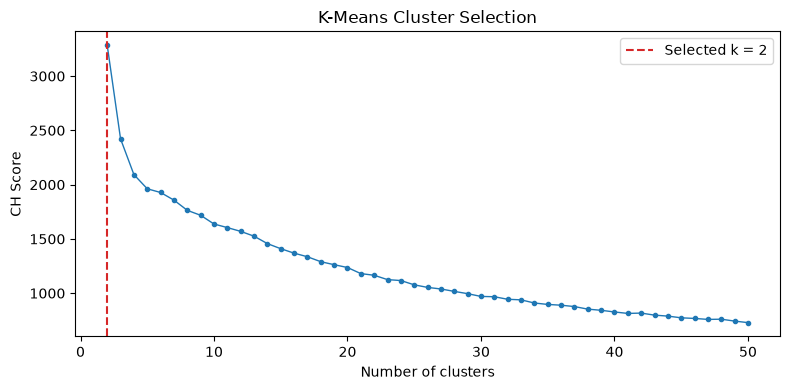

In [14]:
first_kmeans, k_search = choose_kmeans(RANDOM_STATE)

print("Selected k:", first_kmeans.n_clusters)

display(
    k_search.sort_values(
        "CH Score",
        ascending=False
    ).head(5).reset_index(drop=True).round(4)
)

plt.figure(figsize=(8, 4))

plt.plot(
    k_search["k"],
    k_search["CH Score"],
    marker=".",
    linewidth=1
)

plt.axvline(
    first_kmeans.n_clusters,
    color="tab:red",
    linestyle="--",
    label=f"Selected k = {first_kmeans.n_clusters}"
)

plt.xlabel("Number of clusters")
plt.ylabel("CH Score")
plt.title("K-Means Cluster Selection")
plt.legend()
plt.tight_layout()
plt.show()

The first run selects k = 2 because it has the highest CH score among the candidates.

### (b) Assign Majority Labels

For each cluster, I find the most common Family, Genus, and Species separately. These three values form the cluster's label triplet.

I assign this triplet to every sample in that cluster. If there is a tie, I choose the first label in alphabetical order.

The true labels are used only after clustering and selecting k.

### (c) Evaluate the Cluster Labels

I compare each sample's assigned triplet with its true triplet.

I calculate the average Hamming Distance, Hamming Score, and Hamming Loss across all 7195 samples. I use the same metric definitions as in Question 1.

In [15]:
def assign_cluster_labels(cluster_ids):
    cluster_data = y[label_cols].copy()
    cluster_data["Cluster"] = cluster_ids

    majority_labels = cluster_data.groupby("Cluster")[label_cols].agg(
        lambda values: values.mode().iloc[0]
    )

    predictions = majority_labels.loc[
        cluster_ids, label_cols
    ].reset_index(drop=True)

    predictions.index = y.index

    summary = majority_labels.copy()
    summary.insert(
        0,
        "Samples",
        cluster_data.groupby("Cluster").size()
    )

    return predictions, summary

first_cluster_predictions, first_cluster_summary = assign_cluster_labels(
    first_kmeans.labels_
)

first_cluster_metrics = evaluate_predictions(
    y[label_cols],
    first_cluster_predictions[label_cols]
)

print("Majority labels for each cluster:")
display(first_cluster_summary)

print("First-run clustering results:")
display(first_cluster_metrics.to_frame("Value").round(6))

Majority labels for each cluster:


,Samples,Family,Genus,Species
Cluster,,,,
0,3567,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,3628,Hylidae,Hypsiboas,HypsiboasCordobae


First-run clustering results:


,Value
Exact Match,0.635441
Hamming Distance,0.894093
Hamming Loss,0.298031
Hamming Score,0.701969
Sample Jaccard,0.681918


### Monte Carlo Simulation

I repeat the full procedure 50 times using random seeds from 42 to 91. The first run shown above is included as run 1.

In each run, I search for k again using the CH score. I then assign majority labels and calculate the Hamming metrics.

The dataset stays the same across runs. The random seed changes the K-means initializations.

I report the mean and sample standard deviation of the 50 results. I use ddof = 1 for the standard deviation.

In [16]:
mc_rows = []

for run in range(50):
    seed = RANDOM_STATE + run

    if run == 0:
        model = first_kmeans
    else:
        model, _ = choose_kmeans(seed)

    predictions, _ = assign_cluster_labels(model.labels_)

    metrics = evaluate_predictions(
        y[label_cols],
        predictions[label_cols]
    )

    mc_rows.append({
        "Run": run + 1,
        "Seed": seed,
        "k": model.n_clusters,
        **metrics.to_dict()
    })

    if run == 0 or (run + 1) % 5 == 0:
        print(
            f"Completed {run + 1}/50 runs. "
            f"k={model.n_clusters}, "
            f"Hamming Distance={metrics['Hamming Distance']:.6f}",
            flush=True
        )

mc_results = pd.DataFrame(mc_rows).set_index("Run")

mc_metric_cols = [
    "Hamming Distance",
    "Hamming Score",
    "Hamming Loss"
]

mc_summary = pd.DataFrame({
    "Mean": mc_results[mc_metric_cols].mean(),
    "Std": mc_results[mc_metric_cols].std(ddof=1)
})

k_frequency = (
    mc_results["k"]
    .value_counts()
    .sort_index()
    .rename("Runs")
    .to_frame()
)

k_frequency.index.name = "Selected k"

print("First five runs:")
display(mc_results.head().round(6))

print("Summary of 50 runs:")
display(mc_summary.round(6))

print("Frequency of selected k:")
display(k_frequency)

Completed 1/50 runs. k=2, Hamming Distance=0.894093
Completed 5/50 runs. k=2, Hamming Distance=0.894093
Completed 10/50 runs. k=2, Hamming Distance=0.894093
Completed 15/50 runs. k=2, Hamming Distance=0.894093
Completed 20/50 runs. k=2, Hamming Distance=0.894093
Completed 25/50 runs. k=2, Hamming Distance=0.894093
Completed 30/50 runs. k=2, Hamming Distance=0.894093
Completed 35/50 runs. k=2, Hamming Distance=0.894093
Completed 40/50 runs. k=2, Hamming Distance=0.894093
Completed 45/50 runs. k=2, Hamming Distance=0.894093
Completed 50/50 runs. k=2, Hamming Distance=0.894093
First five runs:


,Seed,k,Exact Match,Hamming Distance,Hamming Loss,Hamming Score,Sample Jaccard
Run,,,,,,,
1,42,2,0.635441,0.894093,0.298031,0.701969,0.681918
2,43,2,0.635441,0.894093,0.298031,0.701969,0.681918
3,44,2,0.635441,0.894093,0.298031,0.701969,0.681918
4,45,2,0.635441,0.894093,0.298031,0.701969,0.681918
5,46,2,0.635441,0.894093,0.298031,0.701969,0.681918


Summary of 50 runs:


,Mean,Std
Hamming Distance,0.894093,0.0
Hamming Score,0.701969,0.0
Hamming Loss,0.298031,0.0


Frequency of selected k:


,Runs
Selected k,
2,50


All 50 runs select k = 2 using the CH score.

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Hamming Distance | 0.894093 | 0.000000 |
| Hamming Score | 0.701969 | 0.000000 |
| Hamming Loss | 0.298031 | 0.000000 |

The Hamming metrics are the same across the tested seeds at six decimal places. Changing the initialization seed does not always change the final results.

On average, about 70.20% of the assigned labels are correct. There are about 0.89 wrong labels per sample out of three labels.

The two clusters capture broad groups in the features. They do not separate all the Family, Genus, and Species classes. The CH score measures cluster structure, so its selected k does not have to match the number of true classes.

## 3. ISLR 12.6.2

### (a) Complete Linkage

Complete linkage uses the largest pairwise dissimilarity between two clusters.

First, observations 1 and 2 merge at height 0.30.

The distance from {1, 2} to observation 3 is max(0.40, 0.50) = 0.50. The distance to observation 4 is max(0.70, 0.80) = 0.80.

Observations 3 and 4 merge next at height 0.45. Finally, {1, 2} and {3, 4} merge at height 0.80.

### (b) Single Linkage

Single linkage uses the smallest pairwise dissimilarity between two clusters.

First, observations 1 and 2 merge at height 0.30.

The distance from {1, 2} to observation 3 is min(0.40, 0.50) = 0.40. Therefore, observation 3 joins this cluster at height 0.40.

Observation 4 joins at height min(0.70, 0.80, 0.45) = 0.45.

### (c) Two Clusters with Complete Linkage

Cutting the tree at height 0.60 gives {1, 2} and {3, 4}.

### (d) Two Clusters with Single Linkage

Cutting the tree at height 0.425 gives {1, 2, 3} and {4}.

### (e) An Equivalent Dendrogram

An equivalent complete-linkage tree can have leaf order 2, 1, 4, 3.

Swapping the leaves within each pair changes their positions. The merged groups and merge heights stay the same.

Reference: An Introduction to Statistical Learning, second edition, Section 12.6, Exercise 2.

,1,2,3,4
1,0.0,0.3,0.40,0.70
2,0.3,0.0,0.50,0.80
3,0.4,0.5,0.00,0.45
4,0.7,0.8,0.45,0.00


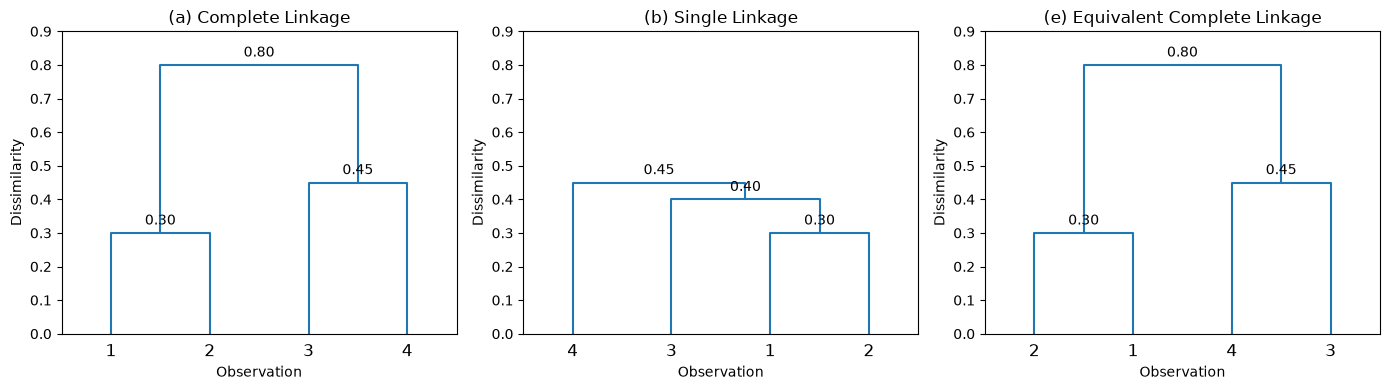

In [17]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

distance_matrix = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00]
])

display(pd.DataFrame(
    distance_matrix,
    index=[1, 2, 3, 4],
    columns=[1, 2, 3, 4]
))

condensed_distances = squareform(distance_matrix)

Z_complete = linkage(
    condensed_distances,
    method="complete"
)

Z_single = linkage(
    condensed_distances,
    method="single"
)

Z_equivalent = Z_complete.copy()

for row in range(2):
    Z_equivalent[row, 0], Z_equivalent[row, 1] = (
        Z_equivalent[row, 1],
        Z_equivalent[row, 0]
    )

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

trees = [Z_complete, Z_single, Z_equivalent]
titles = [
    "(a) Complete Linkage",
    "(b) Single Linkage",
    "(e) Equivalent Complete Linkage"
]

for ax, tree, title in zip(axes, trees, titles):
    diagram = dendrogram(
        tree,
        labels=["1", "2", "3", "4"],
        ax=ax,
        color_threshold=0,
        above_threshold_color="tab:blue"
    )

    for xs, ys in zip(diagram["icoord"], diagram["dcoord"]):
        height = ys[1]

        ax.text(
            (xs[1] + xs[2]) / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

    ax.set_title(title)
    ax.set_xlabel("Observation")
    ax.set_ylabel("Dissimilarity")
    ax.set_ylim(0, 0.90)

plt.tight_layout()
plt.show()